**WandB training curves without manual CSV download**

Run `wandb login` once before using this notebook.

In [3]:
from pathlib import Path
import os
import sys

FIGURES_DIR = Path.cwd()
if FIGURES_DIR.name != "figures" and (FIGURES_DIR / "figures").exists():
    FIGURES_DIR = FIGURES_DIR / "figures"
os.chdir(FIGURES_DIR)
sys.path.insert(0, str(FIGURES_DIR))

import importlib
import wandb_training_curves
importlib.reload(wandb_training_curves)

from wandb_training_curves import (
    DEFAULT_ENTITY,
    build_plot_config,
    fetch_wandb_training_curves,
    plot,
    print_performance_table,
    plot_final_distribution,
    plot_horizontal_legend
)

ENTITY = DEFAULT_ENTITY

**Stag Hunt**

[filter] exclude run name containing: noise0.1
[filter] exclude run name suffix: _noise0.1
[collect] r_ippo     r_ippo_stag-hunt_seed2 (751 points)
[collect] r_ippo     r_ippo_stag-hunt_seed31 (751 points)
[collect] r_ippo     r_ippo_stag-hunt_seed32 (751 points)
[collect] r_ippo     r_ippo_stag-hunt_seed1 (751 points)
[collect] r_ippo     r_ippo_stag-hunt_seed42 (751 points)
[collect] r_mappo    r_mappo_stag-hunt_seed31 (751 points)
[collect] r_mappo    r_mappo_stag-hunt_seed42 (751 points)
[collect] r_mappo    r_mappo_stag-hunt_seed1 (751 points)
[collect] r_mappo    r_mappo_stag-hunt_seed2 (751 points)
[collect] r_mappo    r_mappo_stag-hunt_seed32 (751 points)
[collect] PCI_rippo  PCI_rippo_stag-hunt_seed42 (751 points)
[collect] PCI_rippo  PCI_rippo_stag-hunt_seed1 (751 points)
[collect] PCI_rippo  PCI_rippo_stag-hunt_seed32 (751 points)
[collect] PCI_rippo  PCI_rippo_stag-hunt_seed2 (751 points)
[collect] PCI_rippo  PCI_rippo_stag-hunt_seed31 (751 points)
[collect] PCI_rmappo PCI_

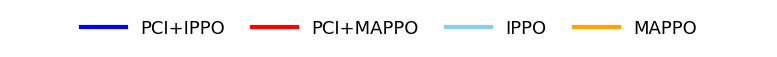

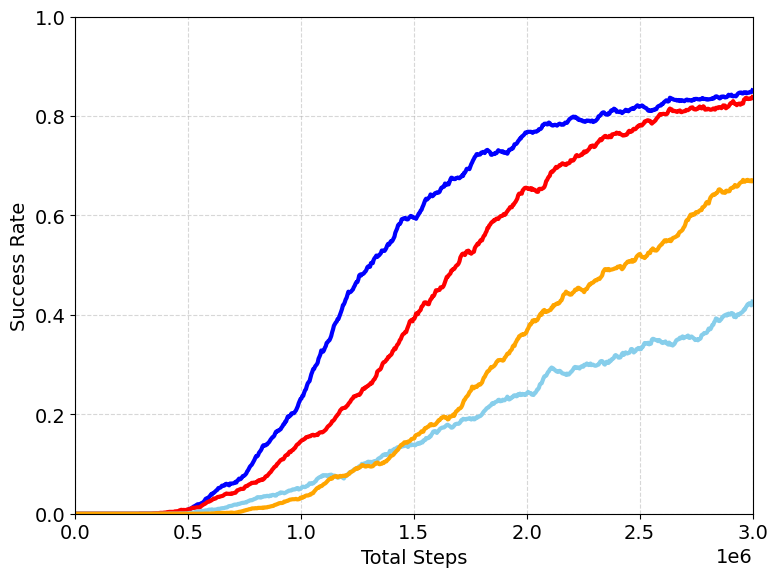

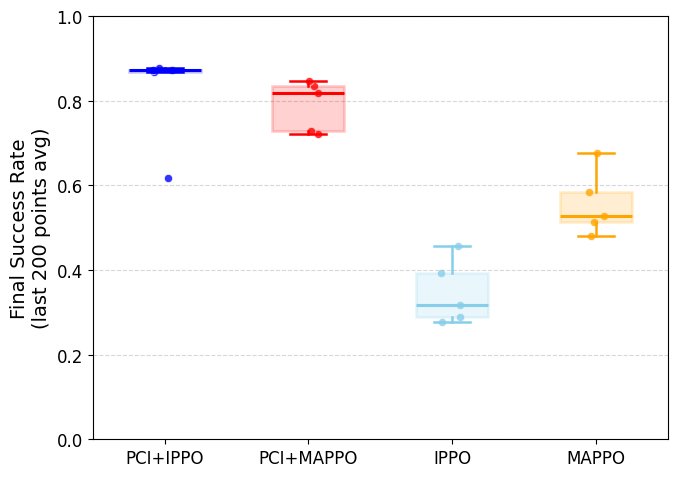


Final Performance Summary (Success Rate)
Based on last 200 points with window_size=20
Algorithm       N     Mean +/- Std    Min      Max     
--------------------------------------------------------------------------------
PCI+IPPO        5     0.822+/-0.102   0.617    0.878   
PCI+MAPPO       5     0.789+/-0.054   0.721    0.845   
IPPO            5     0.347+/-0.069   0.277    0.458   
MAPPO           5     0.556+/-0.069   0.481    0.677   
Note: Values are success rates (0-1 scale)


In [37]:
SH_DIR = Path("wandb_cache/SH")
WINDOW = 20
LAST_N = 200

fetch_wandb_training_curves(
    preset="sh",
    entity=ENTITY,
    output_dir=SH_DIR,
    state="finished",
)

sh_config = build_plot_config("sh", SH_DIR)

# Extract model legend
plot_horizontal_legend(
    sh_config,
    figsize=(8, 0.8),
)

# main figure
plot(
    sh_config, 
    figsize=(8, 6), 
    window_size=WINDOW, 
    ylim=(0,1),
    xlim=(0, 3e6), 
    mean_only=True)

# 2) final performance distribution
plot_final_distribution(
    sh_config,
    window_size=WINDOW,
    last_n=LAST_N,
    figsize=(7, 5),
    ylim=(0, 1),
)

# 3) summary table
print_performance_table(
    sh_config,
    window_size=WINDOW,
    last_n=LAST_N,
)

**Stag Hunt with Observation Noise**

This cell collects only finished StagHunt runs whose run name ends with `_noise0.1`.

[filter] include run name containing: noise0.1
[collect] r_mappo    r_mappo_stag-hunt_seed32_noise0.1 (751 points)
[collect] r_mappo    r_mappo_stag-hunt_seed31_noise0.1 (751 points)
[collect] r_mappo    r_mappo_stag-hunt_seed1_noise0.1 (751 points)
[collect] r_mappo    r_mappo_stag-hunt_seed2_noise0.1 (751 points)
[collect] r_ippo     r_ippo_stag-hunt_seed32_noise0.1 (751 points)
[collect] r_ippo     r_ippo_stag-hunt_seed1_noise0.1 (751 points)
[collect] r_ippo     r_ippo_stag-hunt_seed31_noise0.1 (751 points)
[collect] r_ippo     r_ippo_stag-hunt_seed2_noise0.1 (751 points)
[collect] r_ippo     r_ippo_stag-hunt_seed42_noise0.1 (751 points)
[collect] PCI_rippo  PCI_rippo_stag-hunt_seed42_noise0.1 (751 points)
[collect] PCI_rippo  PCI_rippo_stag-hunt_seed1_noise0.1 (751 points)
[collect] PCI_rippo  PCI_rippo_stag-hunt_seed2_noise0.1 (751 points)
[collect] PCI_rippo  PCI_rippo_stag-hunt_seed31_noise0.1 (751 points)
[collect] PCI_rippo  PCI_rippo_stag-hunt_seed32_noise0.1 (751 points)
[c

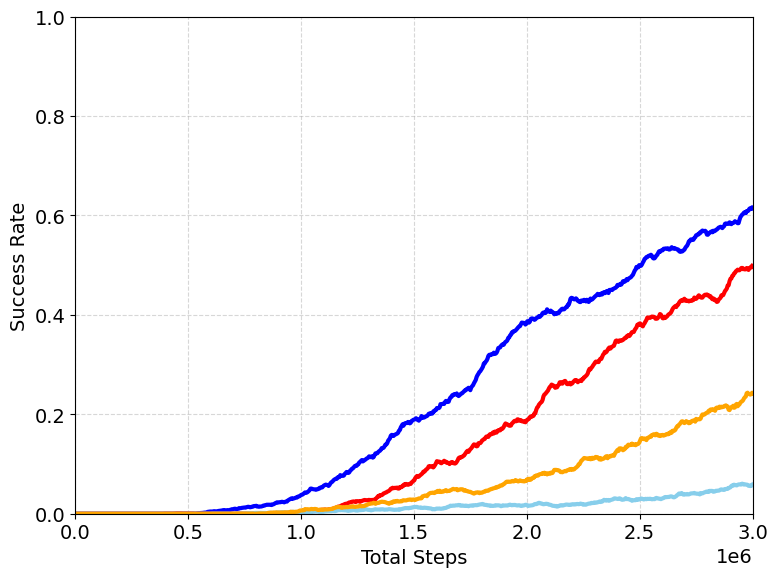

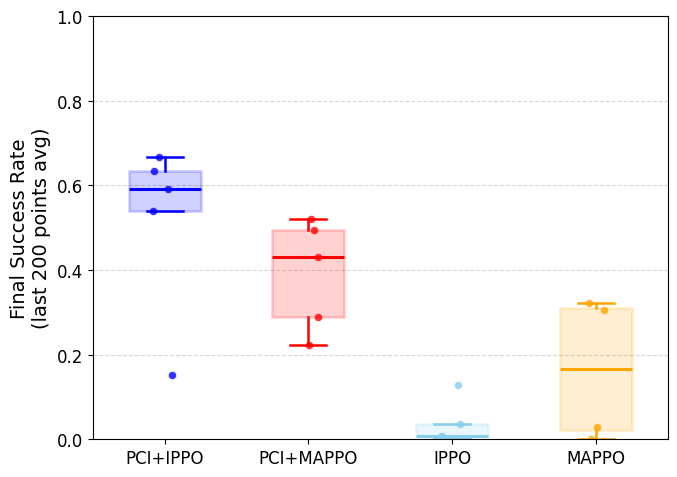


Final Performance Summary (Success Rate)
Based on last 200 points with window_size=20
Algorithm       N     Mean +/- Std    Min      Max     
--------------------------------------------------------------------------------
PCI+IPPO        5     0.517+/-0.187   0.152    0.668   
PCI+MAPPO       5     0.392+/-0.116   0.224    0.522   
IPPO            5     0.036+/-0.047   0.002    0.128   
MAPPO           4     0.164+/-0.150   0.000    0.322   
Note: Values are success rates (0-1 scale)


In [38]:
SH_NOISE_DIR = Path("wandb_cache/SH_noise0.1")

fetch_wandb_training_curves(
    preset="sh-noise",
    entity=ENTITY,
    output_dir=SH_NOISE_DIR,
    state="finished",
)

sh_noise_config = build_plot_config("sh-noise", SH_NOISE_DIR)

plot(
    sh_noise_config, 
    figsize=(8, 6), 
    window_size=WINDOW, 
    ylim=(0,1),
    xlim=(0, 3e6), 
    mean_only=True)

# 2) final performance distribution
plot_final_distribution(
    sh_noise_config,
    window_size=WINDOW,
    last_n=LAST_N,
    figsize=(7, 5),
    ylim=(0, 1),
)

# 3) summary table
print_performance_table(
    sh_noise_config,
    window_size=WINDOW,
    last_n=LAST_N,
)

**CLI examples**

In [40]:
# !python wandb_training_curves.py --preset sh --plot --save-png sh_training_curve.png
# !python wandb_training_curves.py --preset sh-noise --plot --save-png sh_noise0.1_training_curve.png
# !python wandb_training_curves.py --preset sh --name-suffix _noise0.1 --plot --save-png sh_noise0.1_training_curve.png
# !python wandb_training_curves.py --preset smax --list-runs --contains 2s3z
# !python wandb_training_curves.py --preset smax --contains 2s3z tar_w=4 --plot --save-png smax_2s3z_tarw4.png